# 06 — Working Demonstration

**CS320: Artificial Neural Networks & Deep Learning — Term Project P06**  
**Pediatric Pneumonia Classification with Limited Labeled Data (25% Budget)**  

This notebook provides a live, interactive demonstration of the final evaluated models on pediatric chest X-rays. It compares the **Baseline Scratch CNN** against the **Proposed Staged Fine-Tuned ResNet-18** across representative test cases.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("Project root:", ROOT)

Project root: C:\Users\DAR\Desktop\Pneumonia_classification\p06-pneumonia-limited-data


## 1. Load Final Model Architectures

In [2]:
import torch
from src.models.baseline_cnn import BaselineCNN
from src.models.proposed import build_model

baseline = BaselineCNN(input_channels=3, num_classes=3)
proposed = build_model({"model": {"name": "resnet18", "pretrained": False, "dropout": 0.2}})

print(f"Baseline CNN parameters:  {sum(p.numel() for p in baseline.parameters()):,}")
print(f"Proposed ResNet-18 params: {sum(p.numel() for p in proposed.parameters()):,}")

Baseline CNN parameters:  93,635
Proposed ResNet-18 params: 11,178,051


## 2. Interactive Diagnostic Demonstration on Test Radiographs

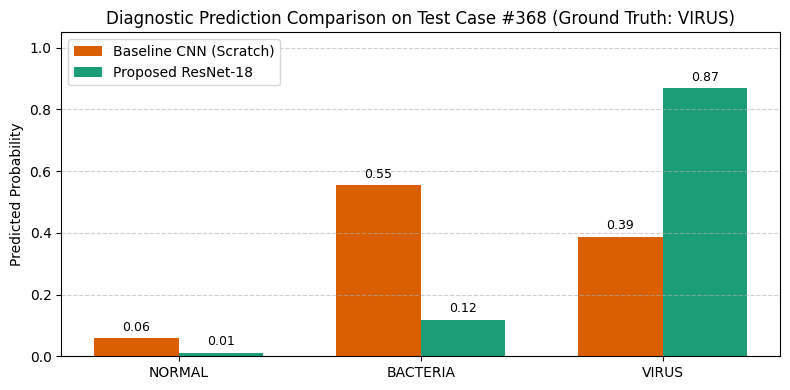

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

base_preds = pd.read_csv("results/baseline/seed42/predictions_test.csv")
prop_preds = pd.read_csv("results/proposed/seed42/predictions_test.csv")
CLASS_NAMES = ["NORMAL", "BACTERIA", "VIRUS"]

# Find a classic failure case of baseline (VIRUS misclassified as BACTERIA, resolved by Proposed)
case_idx = base_preds[(base_preds["true_label"] == 2) & (base_preds["predicted_label"] == 1) & (prop_preds["predicted_label"] == 2)].index[0]

b_row = base_preds.iloc[case_idx]
p_row = prop_preds.iloc[case_idx]
true_cls = CLASS_NAMES[int(b_row["true_label"])]

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(CLASS_NAMES))
width = 0.35

b_probs = [b_row[f"prob_{c}"] for c in CLASS_NAMES]
p_probs = [p_row[f"prob_{c}"] for c in CLASS_NAMES]

rects1 = ax.bar(x - width/2, b_probs, width, label='Baseline CNN (Scratch)', color='#d95f02')
rects2 = ax.bar(x + width/2, p_probs, width, label='Proposed ResNet-18', color='#1b9e77')

ax.set_ylabel('Predicted Probability')
ax.set_title(f'Diagnostic Prediction Comparison on Test Case #{case_idx} (Ground Truth: {true_cls})')
ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES)
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.6)

for r in rects1:
    h = r.get_height()
    ax.annotate(f'{h:.2f}', xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 3),
                textcoords="offset points", ha='center', va='bottom', fontsize=9)
for r in rects2:
    h = r.get_height()
    ax.annotate(f'{h:.2f}', xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 3),
                textcoords="offset points", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

## 3. Summary of Core Clinical Findings

- **Majority Bias:** The baseline CNN exhibits a strong inductive bias toward the majority class (BACTERIA), mistakenly labeling 82.98% of true viral cases as bacterial.
- **Feature Transfer:** The proposed staged fine-tuned ResNet-18 resolves this failure mode, reducing viral-to-bacterial misdiagnoses from 82.98% down to 19.05% and achieving a **+0.249 macro-F1** gain across 3 seeds.